Python : 3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:13:05) [MSC v.1942 64 bit (AMD64)]
PyTorch : 2.15.0+cpu
CUDA disponible : False


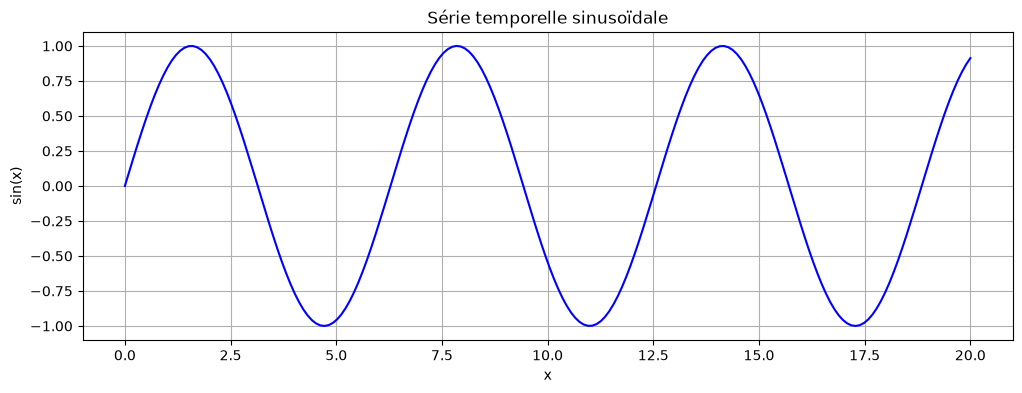

In [1]:
%matplotlib inline

import sys
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

print("Python :", sys.version)
print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())

periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)

plt.figure(figsize=(12, 4))
plt.plot(periode.numpy(), serie.numpy(), color="blue")
plt.title("Série temporelle sinusoïdale")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.grid(True)
plt.show()

## 2. Implémentation d'un RNN

Le RNN (Recurrent Neural Network) est un réseau de neurones
récurrent conçu pour traiter des données séquentielles.

Il traite les éléments d'une séquence successivement en
conservant un état caché qui contient les informations
des étapes précédentes.

Dans cette partie, nous utilisons un RNN pour prédire la
prochaine valeur de la série temporelle sinusoïdale à partir
des 10 valeurs précédentes.

In [5]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

# Génération de la série temporelle
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)

longueur_sequence = 10

# Création des séquences
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

X = X.unsqueeze(-1)
y = y.unsqueeze(-1)

# Séparation des données
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)
print("X_test  :", X_test.shape)
print("y_test  :", y_test.shape)

X_train : torch.Size([150, 10, 1])
y_train : torch.Size([150, 1])
X_test  : torch.Size([40, 10, 1])
y_test  : torch.Size([40, 1])


In [6]:
class SimpleRNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,
            hidden_size=16,
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.rnn(x)
        dernier_etat = etats[:, -1, :]

        return self.sortie(dernier_etat)


modele_rnn = SimpleRNN()

print(modele_rnn)

SimpleRNN(
  (rnn): RNN(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)


In [7]:
critere = nn.MSELoss()

optimiseur_rnn = torch.optim.Adam(
    modele_rnn.parameters(),
    lr=0.01
)

epochs = 300
historique_rnn = []

In [8]:
modele_rnn.train()

for epoch in range(epochs):

    predictions = modele_rnn(X_train)

    perte = critere(predictions, y_train)

    optimiseur_rnn.zero_grad()

    perte.backward()

    optimiseur_rnn.step()

    historique_rnn.append(perte.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Erreur : {perte.item():.6f}"
        )

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025


In [9]:
modele_rnn.eval()

with torch.no_grad():

    predictions_rnn = modele_rnn(X_test)

    erreur_test_rnn = critere(
        predictions_rnn,
        y_test
    )

print(f"Erreur de test : {erreur_test_rnn.item():.6f}")
print(f"Valeur réelle : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions_rnn[0].item():.4f}")

Erreur de test : 0.000028
Valeur réelle : -0.3639
Valeur prédite : -0.3601


### 2.4. Visualisation des résultats

Nous représentons l'évolution de la fonction de perte
pendant l'entraînement ainsi que la comparaison entre
les valeurs réelles et les prédictions du RNN.

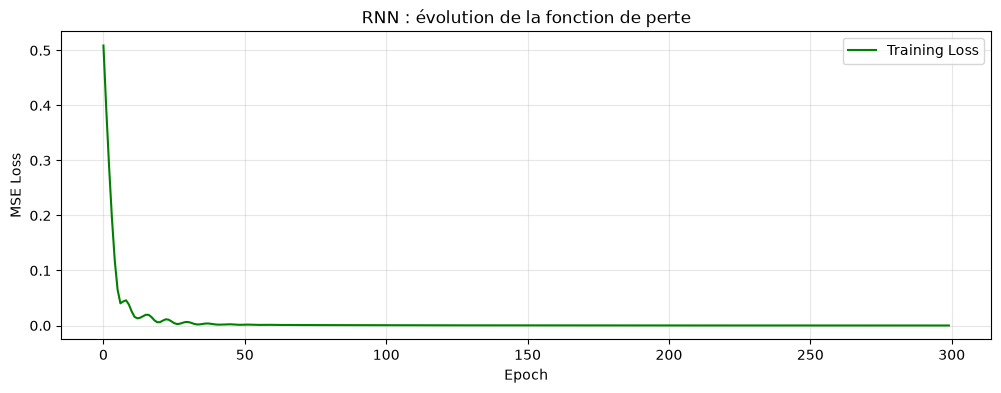

In [10]:
plt.figure(figsize=(12, 4))

plt.plot(
    historique_rnn,
    color="green",
    label="Training Loss"
)

plt.title("RNN : évolution de la fonction de perte")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

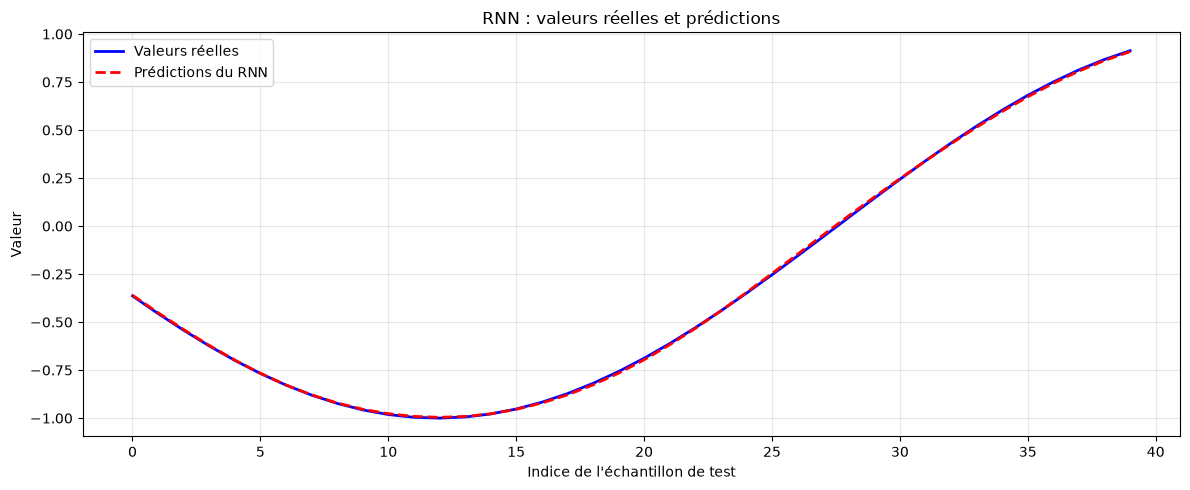

In [11]:
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)

valeurs_predites_rnn = (
    predictions_rnn.detach().cpu().numpy().reshape(-1)
)

plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites_rnn,
    label="Prédictions du RNN",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("RNN : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2.5. Interprétation des résultats

Les résultats montrent que le RNN est capable d'apprendre
les dépendances temporelles de la série sinusoïdale.

La diminution de la fonction de perte indique que le modèle
améliore progressivement ses prédictions pendant l'entraînement.

Les valeurs prédites sont proches des valeurs réelles,
ce qui traduit une bonne capacité de généralisation sur
cette série temporelle simple.

Cependant, les RNN présentent certaines limites :

- Le traitement séquentiel des données.
- La difficulté de capturer les dépendances à long terme.
- Le problème de disparition du gradient (Vanishing Gradient).

Ces limitations motivent l'utilisation des architectures
LSTM et Transformer.